# Customer Segmentation using K-Means Clustering

### An Unsupervised Machine Learning Project (Beginner Friendly)

## What are we trying to do?

Imagine you run a shopping mall. You have data on hundreds of customers, but only
a few basic details about each one: their **age**, how much money they earn
(**annual income**), and how much they tend to spend at your mall (**spending score**).

You want to run smart, targeted marketing campaigns, but treating every customer
the same way is wasteful — a high-spender and a rare visitor shouldn't get the same offer.

**The question this project answers:** *Can we automatically group customers into a
handful of meaningful "types" -- without anyone telling us in advance what those types are?*

This is exactly what **unsupervised clustering** does, and we'll use an algorithm
called **K-Means** to do it.

## Supervised vs Unsupervised Learning (in plain words)

- **Supervised learning** -- your data comes with correct "answers" (labels), and the
  model learns to predict that answer for new data. Example: predicting a house price
  when you already know the prices of similar houses sold before.
- **Unsupervised learning** -- your data has **no correct answers/labels** at all. The
  model has to find structure or patterns on its own. Example: grouping similar
  customers together -- nobody tells the model "this customer is Type A", it has to
  figure out the groups itself.

Customer segmentation is a classic unsupervised problem: nobody has already labelled
each customer with their "true" group -- we are discovering the groups.

## What is K-Means, in one paragraph?

K-Means splits data points into **K groups (clusters)** so that:
1. Points **inside** the same group are as close to each other as possible.
2. Points in **different** groups are as far from each other as possible.

Think of sorting a mixed basket of fruit by size and color, without knowing their
names -- the apples end up together, the grapes end up together, purely because
they "look similar" to each other.

Every step below explains **why** we're doing it, not just **how** -- that's the point
of this notebook.


## Step 1: Import the Libraries We Need

**What are we solving here?** Before writing any logic, we need to bring in the
Python tools that will do the heavy lifting for us: reading data, doing math,
drawing charts, and running the clustering algorithm.


In [1]:
# pandas -> lets us load and work with tabular data (like an Excel sheet, but in code)
import pandas as pd

# numpy -> lets us do fast numerical/array operations
import numpy as np

# matplotlib & seaborn -> used for drawing charts so we can SEE our data
import matplotlib.pyplot as plt
import seaborn as sns
%matplotlib inline

# StandardScaler -> puts all our features on the same scale (explained in Step 6)
from sklearn.preprocessing import StandardScaler

# KMeans -> the actual clustering algorithm we are learning in this project
from sklearn.cluster import KMeans

# silhouette_score -> a metric that tells us how good our clusters are
from sklearn.metrics import silhouette_score

# pickle -> lets us save our trained model to a file so we can reuse it later
import pickle

# just a nicer visual style for our plots
sns.set_style("whitegrid")

print("All libraries imported successfully!")


All libraries imported successfully!


## Step 2: Load the Dataset

**What are we solving here?** We need real customer data to work with. We're using
the classic **Mall Customers dataset** -- basic details on 200 customers of a
shopping mall. It's the standard beginner dataset for this exact problem.

**Columns in this dataset:**

| Column | Meaning |
|---|---|
| `CustomerID` | A unique number per customer (just an ID -- not useful information) |
| `Gender` | Male / Female |
| `Age` | Customer's age in years |
| `Annual Income (k$)` | Customer's yearly income, in thousands of dollars |
| `Spending Score (1-100)` | A score the mall itself assigns to each customer (1 = spends very little, 100 = spends a lot), based on their shopping behaviour |


In [2]:
import os

# A friendly check so that if you move this notebook without the CSV,
# you get a clear error instead of a confusing one.
if not os.path.exists('Mall_Customers.csv'):
    raise FileNotFoundError(
        "Mall_Customers.csv not found! Make sure the CSV file is in the same "
        "folder as this notebook."
    )

# Load the CSV file into a pandas DataFrame (basically a table)
df = pd.read_csv('Mall_Customers.csv')

# Look at the first 5 rows to see what the data looks like
df.head()


,CustomerID,Gender,Age,Annual Income (k$),Spending Score (1-100)
0,1,Male,19,15,39
1,2,Male,21,15,81
2,3,Female,20,16,6
3,4,Female,23,16,77
4,5,Female,31,17,40


## Step 3: Explore the Data (EDA)

**What are we solving here?** Before building any model, we ALWAYS look closely at
the data first. This helps us catch problems (missing values, weird values) and
understand what we're working with. This is called **Exploratory Data Analysis (EDA)**.


In [3]:
# How many rows and columns do we have?
print("Shape of the dataset (rows, columns):", df.shape)

# What data type is each column, and are there any missing values?
print("\nColumn info:")
df.info()


Shape of the dataset (rows, columns): (200, 5)

Column info:
<class 'pandas.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 5 columns):
 #   Column                  Non-Null Count  Dtype
---  ------                  --------------  -----
 0   CustomerID              200 non-null    int64
 1   Gender                  200 non-null    str  
 2   Age                     200 non-null    int64
 3   Annual Income (k$)      200 non-null    int64
 4   Spending Score (1-100)  200 non-null    int64
dtypes: int64(4), str(1)
memory usage: 7.9 KB


In [4]:
# Summary statistics (mean, min, max, etc.) for the numeric columns
df.describe()


,CustomerID,Age,Annual Income (k$),Spending Score (1-100)
count,200.000000,200.000000,200.000000,200.000000
mean,100.500000,38.850000,60.560000,50.200000
std,57.879185,13.969007,26.264721,25.823522
min,1.000000,18.000000,15.000000,1.000000
25%,50.750000,28.750000,41.500000,34.750000
50%,100.500000,36.000000,61.500000,50.000000
75%,150.250000,49.000000,78.000000,73.000000
max,200.000000,70.000000,137.000000,99.000000


In [5]:
# Double-check: are there any missing (empty) values in any column?
print("Missing values in each column:")
print(df.isnull().sum())
# If every number here is 0, our data is clean and we don't need to fix anything.


Missing values in each column:
CustomerID                0
Gender                    0
Age                       0
Annual Income (k$)        0
Spending Score (1-100)    0
dtype: int64


## Step 4: Visualize the Data

**What are we solving here?** Numbers in a table are hard for our brain to read.
Charts make patterns jump out visually. We want to "get a feel" for the data
before we start modelling anything.


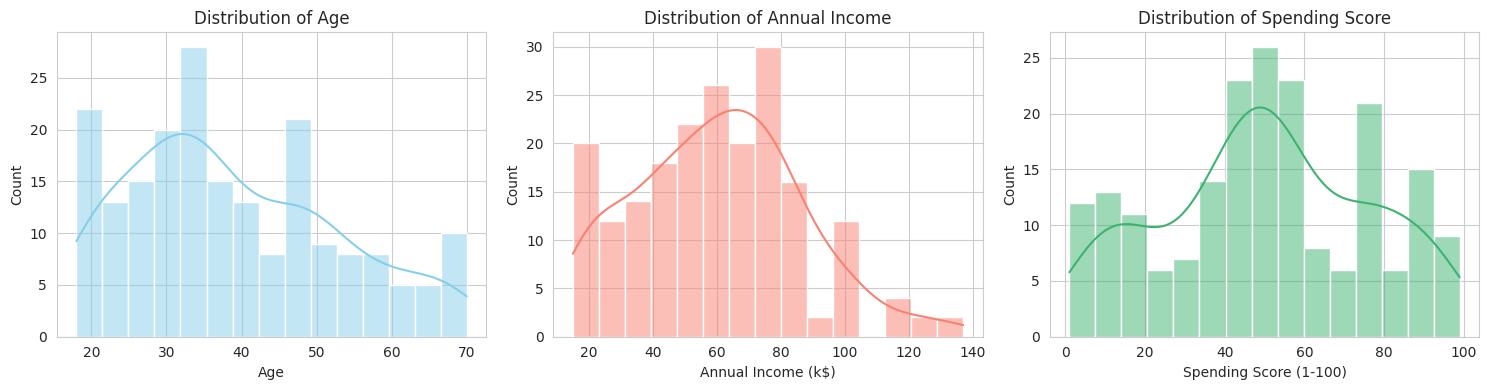

In [6]:
# Distribution of Age, Annual Income, and Spending Score
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

sns.histplot(df['Age'], bins=15, kde=True, ax=axes[0], color='skyblue')
axes[0].set_title('Distribution of Age')

sns.histplot(df['Annual Income (k$)'], bins=15, kde=True, ax=axes[1], color='salmon')
axes[1].set_title('Distribution of Annual Income')

sns.histplot(df['Spending Score (1-100)'], bins=15, kde=True, ax=axes[2], color='mediumseagreen')
axes[2].set_title('Distribution of Spending Score')

plt.tight_layout()
plt.show()
# A histogram shows how values are spread out -- for example, which age range
# has the most customers.


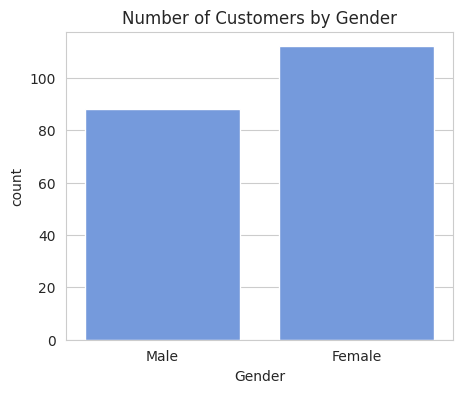

In [7]:
# How many male vs female customers do we have?
plt.figure(figsize=(5, 4))
sns.countplot(data=df, x='Gender', color='cornflowerblue')
plt.title('Number of Customers by Gender')
plt.show()


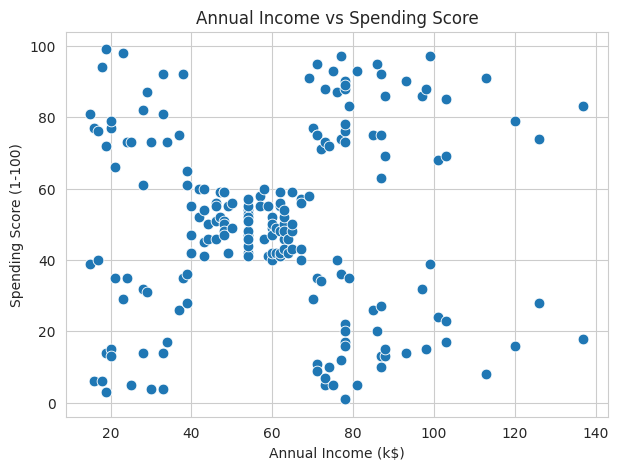

In [8]:
# This is the MOST IMPORTANT chart for our project.
# We plot Annual Income against Spending Score to see if natural "groups" of
# customers are visible even to the naked eye.
plt.figure(figsize=(7, 5))
sns.scatterplot(data=df, x='Annual Income (k$)', y='Spending Score (1-100)', s=60)
plt.title('Annual Income vs Spending Score')
plt.show()

# Take a moment to look at this plot -- can you already see roughly 5 "blobs"
# of points? That's exactly what K-Means is going to find for us automatically,
# using math instead of our eyes.


## Step 5: Select the Features for Clustering

**What are we solving here?** K-Means needs to know WHICH columns to use to
measure "similarity" between customers. We can't use every column blindly:

- `CustomerID` -- just a label, has no real meaning, so we drop it.
- `Gender` -- not a number, and to keep this beginner project simple, we'll use it
  later just to *understand* the clusters, not to *create* them.
- `Age`, `Annual Income`, `Spending Score` -- all real numeric characteristics.

To keep things simple and easy to **visualize in 2D**, we will cluster customers using just:

- **Annual Income (k$)**
- **Spending Score (1-100)**

(There's a "Try it yourself" idea at the end of this notebook about adding `Age` too.)


In [9]:
# Select just the two columns we want to cluster on
X = df[['Annual Income (k$)', 'Spending Score (1-100)']]

X.head()


,Annual Income (k$),Spending Score (1-100)
0,15,39
1,15,81
2,16,6
3,16,77
4,17,40


## Step 6: Feature Scaling

**What are we solving here?** K-Means decides which cluster a point belongs to by
measuring the **distance** between points (straight-line / Euclidean distance).

If one column has much bigger numbers than another, it will unfairly dominate that
distance calculation, and the algorithm will effectively ignore the smaller-scale column.

**Solution:** we rescale every feature so it has a mean of 0 and a standard deviation
of 1. This puts all features on equal footing. This is called **Standardization**,
and it's good practice for pretty much every distance-based algorithm (K-Means, KNN,
etc.) -- worth doing as a habit, even here where the raw ranges happen to look fairly similar.


In [10]:
# Create the scaler
scaler = StandardScaler()

# fit_transform does two things:
#   1. "fit"       -> learns the mean and standard deviation of each column
#   2. "transform" -> actually rescales the data using those values
X_scaled = scaler.fit_transform(X)

# Peek at the first 5 scaled rows
print(X_scaled[:5])
# Notice the numbers are now roughly between -2 and 2, centered around 0,
# instead of being in the original "dollars" and "score" units.


[[-1.73899919 -0.43480148]
 [-1.73899919  1.19570407]
 [-1.70082976 -1.71591298]
 [-1.70082976  1.04041783]
 [-1.66266033 -0.39597992]]


## Step 7: Find the Best Number of Clusters -- The Elbow Method

**What are we solving here?** K-Means needs us to tell it **how many clusters (K)**
to look for -- it doesn't decide this on its own. So the big question is: **what's
the right K for our data?**

We use a technique called the **Elbow Method**:

1. Try K-Means with K = 1, 2, 3, ... up to some maximum (say 10).
2. For each K, measure the **WCSS** (Within-Cluster Sum of Squares) -- a number that
   tells us how "tight" the clusters are (the total squared distance of every point
   from its own cluster's center). Lower WCSS = tighter clusters.
3. As K increases, WCSS always goes down (more clusters = smaller, tighter groups).
   But after a point, adding more clusters barely helps.
4. Plotting K vs WCSS gives a bent-arm shape -- the "elbow" (the bend) is usually the
   best choice for K. Past the elbow we're just overcomplicating the model for very
   little benefit.


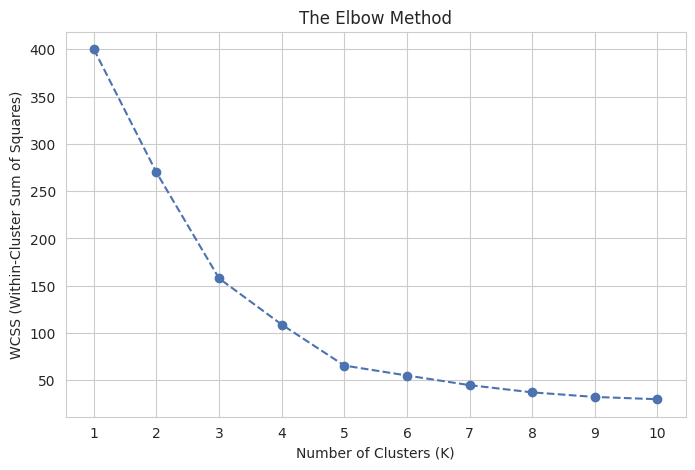

In [11]:
wcss = []  # will store the WCSS value for each K we try

k_range = range(1, 11)  # test K from 1 to 10

for k in k_range:
    kmeans_test = KMeans(n_clusters=k, init='k-means++', random_state=42, n_init=10)
    kmeans_test.fit(X_scaled)
    wcss.append(kmeans_test.inertia_)  # inertia_ is scikit-learn's name for WCSS

# Plot K (x-axis) vs WCSS (y-axis)
plt.figure(figsize=(8, 5))
plt.plot(k_range, wcss, marker='o', linestyle='--', color='#4C72B0')
plt.title('The Elbow Method')
plt.xlabel('Number of Clusters (K)')
plt.ylabel('WCSS (Within-Cluster Sum of Squares)')
plt.xticks(list(k_range))
plt.show()

# Look for the point where the line stops dropping sharply and starts to flatten
# out -- that "elbow" is our best guess for K.


## Step 8: Double-Check with the Silhouette Score

**What are we solving here?** The elbow method involves a bit of "eyeballing" the
chart, which feels subjective. Let's confirm our choice with a second, more precise
metric: the **Silhouette Score**.

For each customer, this score compares:
- how close they are to other customers **in their own cluster**, vs.
- how close they are to customers **in the nearest other cluster**.

The score ranges from **-1 to 1**:
- **Close to 1** -> fits its own cluster well and is far from other clusters (great).
- **Close to 0** -> sits right on the border between two clusters.
- **Negative** -> probably in the wrong cluster.

We compute the *average* silhouette score across all customers, for each K, and pick
the K with the highest score. (This score needs at least 2 clusters, so we start at K=2.)


K = 2 -> Silhouette Score = 0.321
K = 3 -> Silhouette Score = 0.467
K = 4 -> Silhouette Score = 0.494
K = 5 -> Silhouette Score = 0.555
K = 6 -> Silhouette Score = 0.540
K = 7 -> Silhouette Score = 0.528
K = 8 -> Silhouette Score = 0.455
K = 9 -> Silhouette Score = 0.457
K = 10 -> Silhouette Score = 0.443


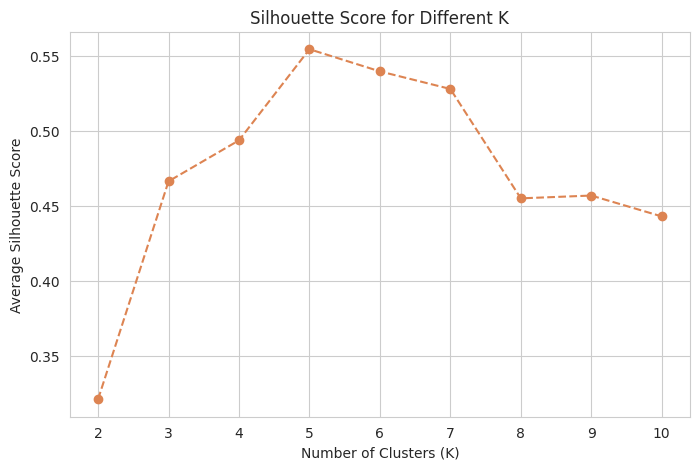

In [12]:
silhouette_scores = []
k_range_sil = range(2, 11)  # silhouette score needs at least 2 clusters

for k in k_range_sil:
    kmeans_test = KMeans(n_clusters=k, init='k-means++', random_state=42, n_init=10)
    labels = kmeans_test.fit_predict(X_scaled)
    score = silhouette_score(X_scaled, labels)
    silhouette_scores.append(score)
    print(f"K = {k} -> Silhouette Score = {score:.3f}")

plt.figure(figsize=(8, 5))
plt.plot(list(k_range_sil), silhouette_scores, marker='o', linestyle='--', color='#DD8452')
plt.title('Silhouette Score for Different K')
plt.xlabel('Number of Clusters (K)')
plt.ylabel('Average Silhouette Score')
plt.xticks(list(k_range_sil))
plt.show()


## Step 9: Train the Final K-Means Model

**What are we solving here?** We now have strong evidence for the best K, from both
the elbow chart and the silhouette scores. Time to train our **final** model with
that value, and actually assign every customer to a cluster.


In [13]:
# Based on the elbow chart (the bend around K=5) and the silhouette scores above:
optimal_k = 5

# Train K-Means with our chosen K
kmeans = KMeans(n_clusters=optimal_k, init='k-means++', random_state=42, n_init=10)

# fit_predict trains the model AND returns the cluster label for every row
cluster_labels = kmeans.fit_predict(X_scaled)

# Add the cluster label back onto our original (unscaled) dataframe, so it's easy to read
df['Cluster'] = cluster_labels

df.head()


,CustomerID,Gender,Age,Annual Income (k$),Spending Score (1-100),Cluster
0,1,Male,19,15,39,4
1,2,Male,21,15,81,2
2,3,Female,20,16,6,4
3,4,Female,23,16,77,2
4,5,Female,31,17,40,4


## Step 10: Visualize the Clusters

**What are we solving here?** Numbers in a `Cluster` column are hard to interpret.
Let's plot the customers again, this time coloring each point by which cluster it
belongs to, so we can literally **see** the segments K-Means found.


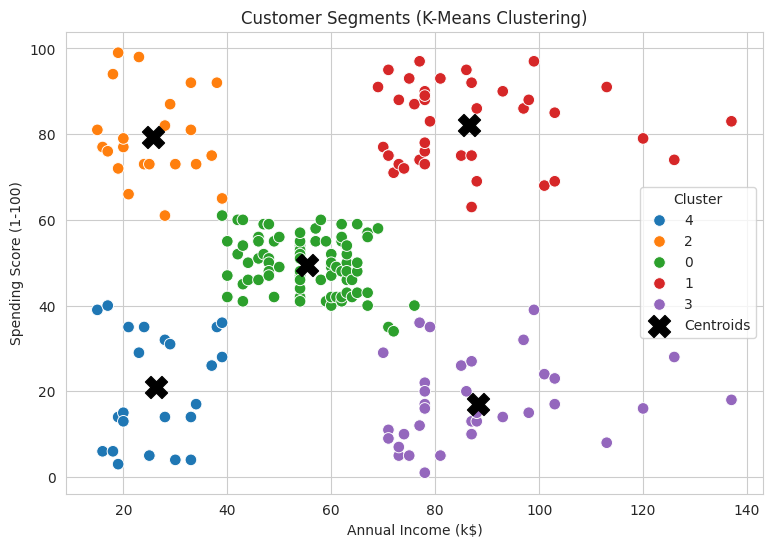

In [14]:
plt.figure(figsize=(9, 6))

# Plot each customer, colored by their cluster (cast to string so the legend
# shows discrete cluster numbers instead of a continuous color scale)
sns.scatterplot(
    data=df, x='Annual Income (k$)', y='Spending Score (1-100)',
    hue=df['Cluster'].astype(str), palette='tab10', s=70
)

# Get the cluster centers back in ORIGINAL units (they were computed on scaled data)
centers_scaled = kmeans.cluster_centers_
centers_original = scaler.inverse_transform(centers_scaled)

# Plot the centroids (the "center point" of each cluster) as black X marks
plt.scatter(
    centers_original[:, 0], centers_original[:, 1],
    marker='X', s=250, c='black', label='Centroids'
)

plt.title('Customer Segments (K-Means Clustering)')
plt.legend(title='Cluster')
plt.show()

# Each color is one "type" of customer. The black X marks are the center of
# each group -- the "average" customer of that segment.


## Step 11: Understand What Each Cluster Actually Means

**What are we solving here?** Five colored blobs on a chart aren't useful to a
business by themselves. The real value comes from translating each cluster's
numbers into a **plain-English description** we can act on (e.g. for marketing).

Let's compute the average Age, Income, and Spending Score for each cluster, and
give each one a sensible name.


In [15]:
# Average feature values per cluster
cluster_summary = df.groupby('Cluster')[['Age', 'Annual Income (k$)', 'Spending Score (1-100)']].mean().round(1)

# How many customers are in each cluster
cluster_summary['Number of Customers'] = df['Cluster'].value_counts().sort_index()

cluster_summary


,Age,Annual Income (k$),Spending Score (1-100),Number of Customers
Cluster,,,,
0,42.7,55.3,49.5,81
1,32.7,86.5,82.1,39
2,25.3,25.7,79.4,22
3,41.1,88.2,17.1,35
4,45.2,26.3,20.9,23


In [16]:
# Let's give each cluster a simple, human-readable name based on whether its
# average income/spending is Low, Medium, or High (splitting the data into
# three equal-sized parts using the 33rd and 66th percentiles).

income_33, income_66 = df['Annual Income (k$)'].quantile([0.33, 0.66])
spending_33, spending_66 = df['Spending Score (1-100)'].quantile([0.33, 0.66])

def bucket(value, low_cut, high_cut):
    # Turns a number into 'Low', 'Medium', or 'High'
    if value <= low_cut:
        return "Low"
    elif value <= high_cut:
        return "Medium"
    else:
        return "High"

def label_cluster(row):
    income_level = bucket(row['Annual Income (k$)'], income_33, income_66)
    spending_level = bucket(row['Spending Score (1-100)'], spending_33, spending_66)
    return f"{income_level} Income, {spending_level} Spending"

cluster_summary['Segment Name'] = cluster_summary.apply(label_cluster, axis=1)
cluster_summary


,Age,Annual Income (k$),Spending Score (1-100),Number of Customers,Segment Name
Cluster,,,,,
0,42.7,55.3,49.5,81,"Medium Income, Medium Spending"
1,32.7,86.5,82.1,39,"High Income, High Spending"
2,25.3,25.7,79.4,22,"Low Income, High Spending"
3,41.1,88.2,17.1,35,"High Income, Low Spending"
4,45.2,26.3,20.9,23,"Low Income, Low Spending"


## Step 12: Save the Trained Model

**What are we solving here?** Right now, our trained model only exists inside this
notebook's memory. If we restart the notebook (or want to use this model somewhere
else, like a small web app), we'd lose it. So we **save ("pickle") it to a file** --
this lets us reload the exact same trained model later without retraining from scratch.

We need to save **both**:
1. The `scaler` (to correctly scale any new customer's data the same way).
2. The `kmeans` model itself (to predict which cluster a new customer belongs to).


In [17]:
# Save the scaler
with open('scaler.pkl', 'wb') as f:
    pickle.dump(scaler, f)

# Save the trained K-Means model
with open('kmeans_model.pkl', 'wb') as f:
    pickle.dump(kmeans, f)

print("Model and scaler saved successfully!")
print("Files created: scaler.pkl, kmeans_model.pkl")


Model and scaler saved successfully!
Files created: scaler.pkl, kmeans_model.pkl


## Bonus: Predict the Segment of a Brand-New Customer

**What are we solving here?** Let's actually use our model! Suppose a brand-new
customer walks in with a known Annual Income and Spending Score -- which segment
would they belong to?


In [18]:
# Example: a new customer with Annual Income = 75k and Spending Score = 80
new_customer = pd.DataFrame({'Annual Income (k$)': [75], 'Spending Score (1-100)': [80]})

# IMPORTANT: scale the new data using the SAME scaler we trained earlier.
# We use .transform (NOT .fit_transform) so it reuses the original mean/std.
new_customer_scaled = scaler.transform(new_customer)

predicted_cluster = kmeans.predict(new_customer_scaled)[0]
segment_name = cluster_summary.loc[predicted_cluster, 'Segment Name']

print(f"This new customer belongs to Cluster {predicted_cluster}: {segment_name}")


This new customer belongs to Cluster 1: High Income, High Spending


## Summary -- What We Did

1. **Loaded** customer data (Age, Income, Spending Score).
2. **Explored** it to understand its shape and check for missing values.
3. **Visualized** it to build intuition before modelling anything.
4. **Selected & scaled** the features so K-Means treats them fairly.
5. **Found the best K** using the Elbow Method, and confirmed it with the Silhouette Score.
6. **Trained** the final K-Means model and assigned every customer to a cluster.
7. **Interpreted** each cluster in plain business language.
8. **Saved** the model so it can be reused without retraining.

## Key Takeaway

K-Means doesn't know anything about "marketing" or "customers" -- it only knows
numbers and distances. **We** are the ones who turn its output (cluster labels
0, 1, 2, 3, 4) into meaningful business insight ("Target Customers", "Budget
Customers", etc.). That translation step is often the most valuable part of a
real-world data science project.

## Ideas to Try Next (Optional)

- Add **Age** as a third feature and see how the clusters change.
- Try a different number of clusters and see how the segments change.
- Try another clustering algorithm, like **Hierarchical Clustering** or **DBSCAN**,
  and compare the results.
- Build a simple **Streamlit app** where you enter a customer's income and spending
  score and instantly see their predicted segment -- happy to help you build this
  next if you'd like!
